In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [5]:
df=pd.read_csv("ecommerce_rfm_unlabeled.csv")

In [6]:
df

,CustomerID,Recency,Frequency,Monetary
0,C10000,230.0,1.0,26.93
1,C10001,12.0,1.0,10.00
2,C10002,21.0,3.0,74.47
3,C10003,13.0,15.0,1586.65
4,C10004,206.0,1.0,21.07
...,...,...,...,...
2055,C12055,18.0,1.0,146.64
2056,C12056,22.0,2.0,208.10
2057,C12057,19.0,3.0,273.27
2058,C12058,6.0,42.0,6149.77


In [7]:
df.head()

,CustomerID,Recency,Frequency,Monetary
0,C10000,230.0,1.0,26.93
1,C10001,12.0,1.0,10.00
2,C10002,21.0,3.0,74.47
3,C10003,13.0,15.0,1586.65
4,C10004,206.0,1.0,21.07


In [8]:
df.shape

(2060, 4)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2060 entries, 0 to 2059
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  2060 non-null   object 
 1   Recency     2060 non-null   float64
 2   Frequency   2060 non-null   float64
 3   Monetary    2060 non-null   float64
dtypes: float64(3), object(1)
memory usage: 64.5+ KB


In [10]:
df.isnull().sum()

,0
CustomerID,0
Recency,0
Frequency,0
Monetary,0


In [11]:
df[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,2060.000000,2060.000000,2060.000000
mean,99.170388,11.957767,1964.198252
std,107.773063,13.965115,3007.156762
min,1.000000,1.000000,10.000000
25%,14.000000,2.000000,181.502500
50%,34.000000,9.000000,1068.600000
75%,176.250000,17.000000,2389.460000
max,365.000000,119.000000,28342.800000


(array([474., 390., 221.,  96.,  27.,   8.,  13.,  26.,  33.,  39.,  39.,
         57.,  43.,  54.,  47.,  30.,  41.,  26.,  32.,  35.,  42.,  42.,
         46.,  43.,  34.,  32.,  22.,  25.,  15.,  28.]),
 array([  1.        ,  13.13333333,  25.26666667,  37.4       ,
         49.53333333,  61.66666667,  73.8       ,  85.93333333,
         98.06666667, 110.2       , 122.33333333, 134.46666667,
        146.6       , 158.73333333, 170.86666667, 183.        ,
        195.13333333, 207.26666667, 219.4       , 231.53333333,
        243.66666667, 255.8       , 267.93333333, 280.06666667,
        292.2       , 304.33333333, 316.46666667, 328.6       ,
        340.73333333, 352.86666667, 365.        ]),
 <BarContainer object of 30 artists>)

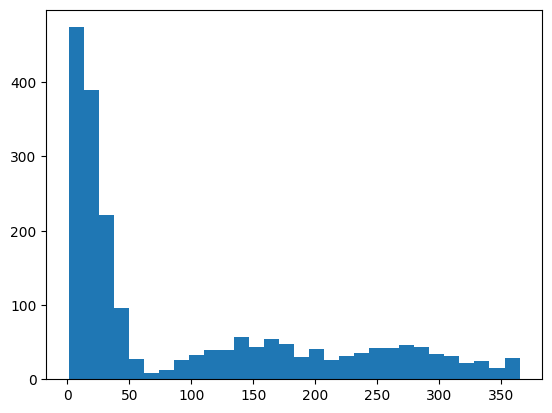

In [12]:
plt.hist(df['Recency'], bins=30)

(array([853., 171., 280., 217., 168.,  98.,  78.,  84.,  43.,  25.,   9.,
          4.,   0.,   0.,   0.,   3.,   2.,   1.,   2.,   0.,   3.,   1.,
          2.,   1.,   4.,   5.,   1.,   1.,   0.,   4.]),
 array([  1.        ,   4.93333333,   8.86666667,  12.8       ,
         16.73333333,  20.66666667,  24.6       ,  28.53333333,
         32.46666667,  36.4       ,  40.33333333,  44.26666667,
         48.2       ,  52.13333333,  56.06666667,  60.        ,
         63.93333333,  67.86666667,  71.8       ,  75.73333333,
         79.66666667,  83.6       ,  87.53333333,  91.46666667,
         95.4       ,  99.33333333, 103.26666667, 107.2       ,
        111.13333333, 115.06666667, 119.        ]),
 <BarContainer object of 30 artists>)

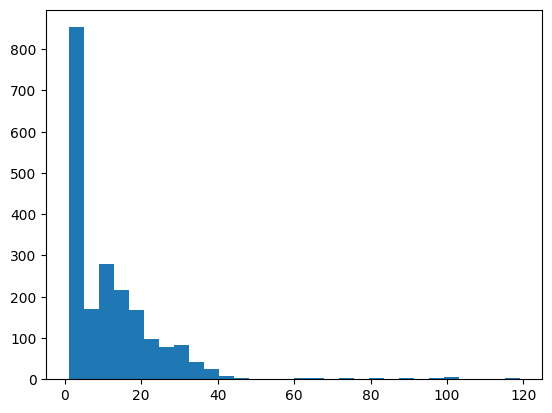

In [13]:
plt.hist(df['Frequency'], bins=30)

(array([975., 400., 252.,  86., 100., 114.,  60.,  20.,   3.,   2.,   4.,
          1.,   4.,   4.,   4.,   6.,   3.,   1.,   2.,   2.,   2.,   4.,
          3.,   1.,   1.,   2.,   1.,   0.,   2.,   1.]),
 array([1.00000000e+01, 9.54426667e+02, 1.89885333e+03, 2.84328000e+03,
        3.78770667e+03, 4.73213333e+03, 5.67656000e+03, 6.62098667e+03,
        7.56541333e+03, 8.50984000e+03, 9.45426667e+03, 1.03986933e+04,
        1.13431200e+04, 1.22875467e+04, 1.32319733e+04, 1.41764000e+04,
        1.51208267e+04, 1.60652533e+04, 1.70096800e+04, 1.79541067e+04,
        1.88985333e+04, 1.98429600e+04, 2.07873867e+04, 2.17318133e+04,
        2.26762400e+04, 2.36206667e+04, 2.45650933e+04, 2.55095200e+04,
        2.64539467e+04, 2.73983733e+04, 2.83428000e+04]),
 <BarContainer object of 30 artists>)

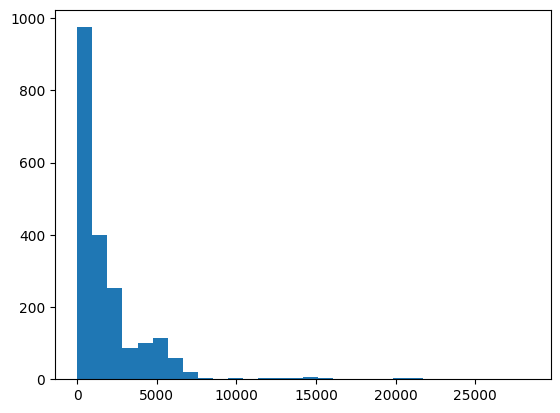

In [14]:
plt.hist(df['Monetary'], bins=30)

In [15]:
from sklearn.preprocessing import StandardScaler

X = df[['Recency', 'Frequency', 'Monetary']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 1.21423085 -0.78484334 -0.64437566]
 [-0.80902919 -0.78484334 -0.65000693]
 [-0.72550011 -0.64159457 -0.62856287]
 [-0.79974818  0.21789807 -0.12558039]
 [ 0.99148663 -0.78484334 -0.64632482]]


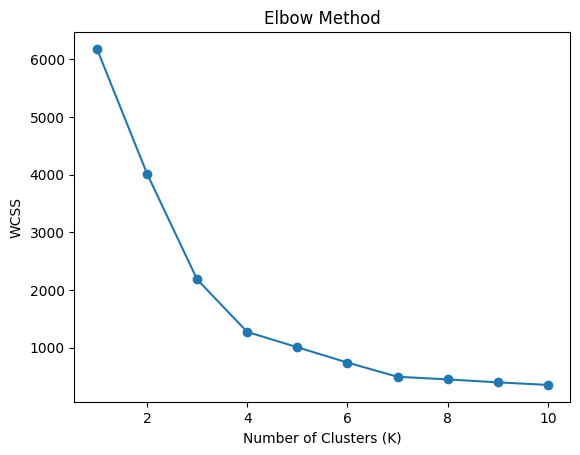

In [16]:

from sklearn.cluster import KMeans


wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()


In [17]:
kmeans = KMeans(n_clusters=7, random_state=42, n_init=10)

labels = kmeans.fit_predict(X_scaled)

df['KMeans_Cluster'] = labels

In [18]:
print(df['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    406
1    304
2    420
3     30
4    383
5    488
6     29
Name: count, dtype: int64


In [19]:
print(df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2))

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                149.59       8.60    966.66
1                 10.28      29.25   4952.58
2                 16.82       2.30    227.75
3                191.77      91.03  19643.66
4                281.62       2.30    176.80
5                 28.32      15.61   2232.46
6                204.55       1.86  10554.40


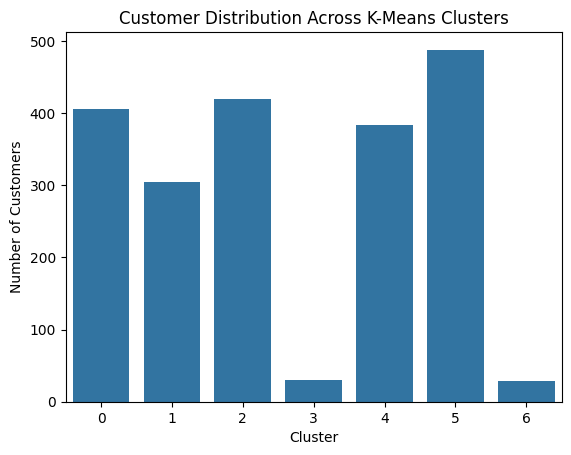

In [20]:

sns.countplot(data=df, x='KMeans_Cluster')
plt.title('Customer Distribution Across K-Means Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

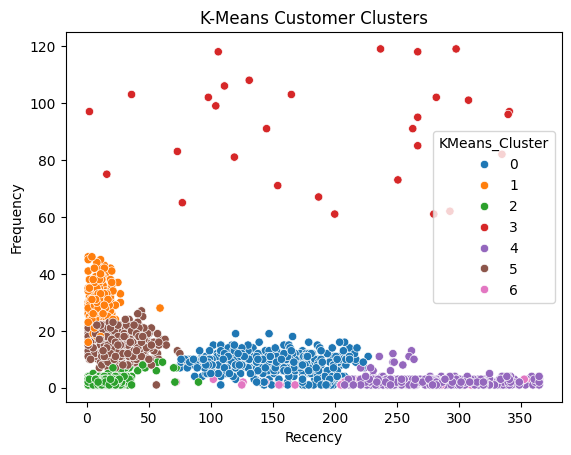

In [21]:
sns.scatterplot(
    data=df,
    x='Recency',
    y='Frequency',
    hue='KMeans_Cluster',
    palette='tab10'
)

plt.title('K-Means Customer Clusters')
plt.show()

In [22]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)

Silhouette Score: 0.5904727200795898


In [23]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.16, min_samples=5)

dbscan_labels = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_labels

In [24]:
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1    137
 0    761
 1    400
 2    747
 3      7
 4      8
Name: count, dtype: int64


In [25]:
print(
    df.groupby('DBSCAN_Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].mean().round(2)
)

                Recency  Frequency  Monetary
DBSCAN_Cluster                              
-1               138.65      30.83   8096.32
 0               213.89       5.35    560.92
 1                15.42       2.10    176.72
 2                21.71      20.22   3158.94
 3                 8.71      42.14   5931.54
 4                 9.38      12.75   4781.74


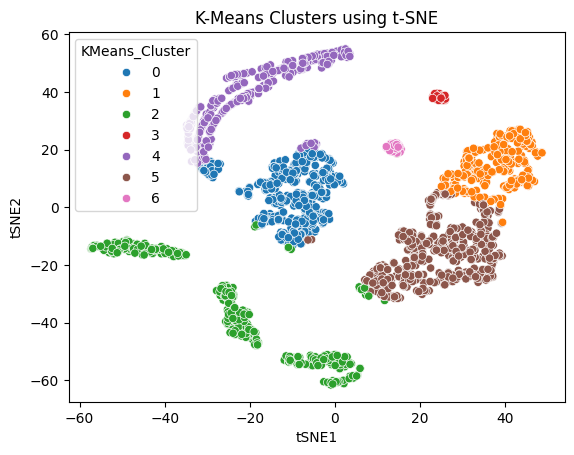

In [26]:

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=['tSNE1', 'tSNE2'])
tsne_df['KMeans_Cluster'] = df['KMeans_Cluster'].values

sns.scatterplot(
    data=tsne_df,
    x='tSNE1',
    y='tSNE2',
    hue='KMeans_Cluster',
    palette='tab10'
)

plt.title('K-Means Clusters using t-SNE')
plt.show()


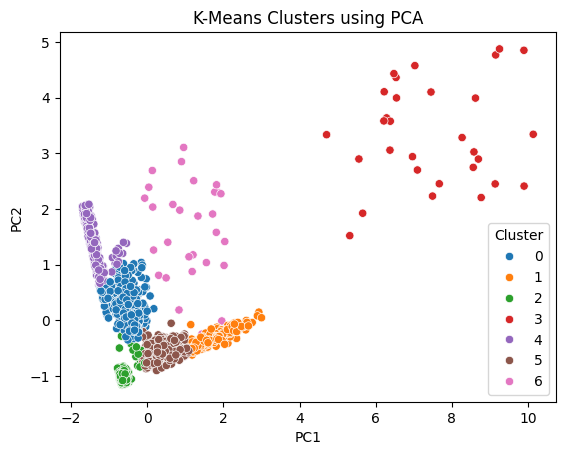

Explained variance ratio: [0.64300059 0.30332591]
Total variance explained: 0.9463265022159619


In [27]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = df['KMeans_Cluster'].values

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='tab10'
)

plt.title('K-Means Clusters using PCA')
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", sum(pca.explained_variance_ratio_))
